Dataset link: [100 Sports Image Classification](https://www.kaggle.com/datasets/gpiosenka/sports-classification?select=sports.csv)

In [ ]:
!pip install torchinfo -q

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split

import torchinfo

In [ ]:
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device:", device)

torch version: 2.11.0+cpu
device: cpu


In [ ]:
from google.colab import userdata
import os

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

!pip install -q kaggle

!mkdir -p dataset

!kaggle datasets download -d gpiosenka/sports-classification -p dataset --unzip

Dataset URL: https://www.kaggle.com/datasets/gpiosenka/sports-classification
License(s): CC0-1.0
100% 424M/424M [00:06<00:00, 71.0MB/s]



# 2. Explorativní analýza dat (EDA)

Načteme soubor `sports.csv`, abychom prozkoumali metadata a strukturu datasetu bez nutnosti načítat všechny neupravené obrázky do RAM najednou.

- **Účel EDA:** Ověřit počty vzorků, prozkoumat rozdělení tříd a potvrdit předdefinované rozdělení na trénovací, validační a testovací sadu.

In [ ]:
df = pd.read_csv("/content/dataset/sports.csv")

In [ ]:
df.head()

,class id,filepaths,labels,data set
0,0,train/air hockey/001.jpg,air hockey,train
1,0,train/air hockey/002.jpg,air hockey,train
2,0,train/air hockey/003.jpg,air hockey,train
3,0,train/air hockey/004.jpg,air hockey,train
4,0,train/air hockey/005.jpg,air hockey,train


## Kontrola vyváženosti a rozdělení datasetu

Analyzujeme rozdělení tříd (sportovních kategorií) napříč jednotlivými sadami (`train`, `valid`, `test`):

- **Struktura rozdělení:** Dataset obsahuje předdefinované rozdělení (~13,5 tis. trénovacích obrázků, 500 validačních obrázků, 500 testovacích obrázků).
- **Vyváženost tříd:** Trénovací sada je **vyvážená** (v průměru ~135 obrázků na třídu s nízkou směrodatnou odchylkou). Díky tomuto rovnoměrnému rozdělení nejsou vyžadovány složité techniky přivyvažování (např. vážené ztrátové funkce); postačí standardní Cross-Entropy Loss.

In [ ]:
print(df['data set'].value_counts())

data set
train    13493
test       500
valid      500
Name: count, dtype: int64


In [ ]:
print("Number of unique sports:", df['labels'].nunique())

Number of unique sports: 100


In [ ]:
class_distribution = pd.crosstab(df['labels'], df['data set'])

LINE_COUNT=5
print(f"Sample image layout for the first {LINE_COUNT} classes")
display(class_distribution.head(LINE_COUNT))

print("\nStatistics on the number of images per class across the individual splits")
print(class_distribution.describe())

Sample image layout for the first 5 classes


data set,test,train,valid
labels,,,
air hockey,5,112,5
ampute football,5,112,5
archery,5,132,5
arm wrestling,5,99,5
axe throwing,5,113,5



Statistics on the number of images per class across the individual splits
data set   test       train  valid
count     100.0  100.000000  100.0
mean        5.0  134.930000    5.0
std         0.0   21.497125    0.0
min         5.0   59.000000    5.0
25%         5.0  120.750000    5.0
50%         5.0  133.500000    5.0
75%         5.0  148.250000    5.0
max         5.0  191.000000    5.0


# 3. Načítání dat & pipeline (PyTorch Dataset & DataLoader)

Definujeme vlastní třídu `SportsDataset`, která dědí z `torch.utils.data.Dataset`.

- **Účel:** Načtení celé kolekce obrázků do RAM najednou by způsobilo chybu nedostatku paměti (out-of-memory). Tato třída implementuje **odložené načítání (lazy loading)**—obrázky se načítají z disku a převádějí do RGB průběžně až ve chvíli, kdy jsou vyžadovány.
- **Mapování štítků:** Automaticky mapuje řetězcové názvy kategorií (např. *air hockey*) na celočíselné indexy (0–99) vyžadované neuronovou sítí.

In [ ]:
from PIL import Image

In [ ]:
class SportsDataset(torch.utils.data.Dataset):
    def __init__(self, csv_file_path, root_dir, split='train', transform=None):
        df = pd.read_csv(csv_file_path)

        # We filter dataframe to keep only needed split ('train', 'valid', or 'test')
        self.df = df[df['data set'] == split].reset_index(drop=True)

        # We filter files that don't have image extensions
        valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
        self.df = self.df[self.df['filepaths'].str.lower().str.endswith(valid_extensions)].reset_index(drop=True)

        self.root_dir = root_dir
        self.transform = transform

        # We create a sorted list of unique classes and a dictionary for text-to-number conversion
        self.classes = sorted(self.df['labels'].unique())
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}

    def __len__(self):
        # Returns the line count of the filtered dataframe
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Loads image from path
        img_path = os.path.join(self.root_dir, row['filepaths'])
        image = Image.open(img_path).convert("RGB")

        # Mapping of image to a numeric value
        label_str = row['labels']
        label = self.class_to_idx[label_str]

        # Aplication of transformation (if its provided)
        if self.transform:
            image = self.transform(image)

        return image, label

## Transformace dat & Nastavení DataLoaderu

Sestavíme pipeline pro předzpracování obrázků pomocí `torchvision.transforms`:

- **Trénovací pipeline (`train_transform`):** Aplikuje náhodné horizontální převrácení (`RandomHorizontalFlip`), rotaci (`RandomRotation`) a úpravy jasu/kontrastu (`ColorJitter`).
  - *Účel:* **Transformace dat** uměle rozšiřuje rozmanitost datasetu, bojuje proti přefitování (overfitting) a zlepšuje generalizaci modelu na dosud neviděných obrázcích.
- **Validační pipeline (`valid_transform`):** Zahrnuje pouze změnu velikosti (`Resize`), převod na tenzor a normalizaci.
  - *Účel:* Udržuje validační vstupy nezkreslené a konzistentní pro spravedlivé vyhodnocení.
- **Normalizace (`Normalize`):** Hodnoty pixelů jsou škálovány pomocí statistik kanálů z ImageNetu (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`).
  - *Účel:* Standardizuje měřítko vstupních příznaků, což vede k rychlejší a stabilnější konvergenci gradientního sestupu.
- **DataLoadery:** Konfigurovány s `batch_size=32`, povoleným náhodným mícháním pro trénování a paralelním načítáním přes `num_workers=2`.

In [ ]:
# We create instances of datasets (without transformations)
train_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='train')
val_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='valid')

print(f"Training image count: {len(train_dataset)}")
print(f"Validation image count: {len(val_dataset)}")
print(f"Class count: {len(train_dataset.classes)}")

# We load 1st sample
img, label = train_dataset[0]

print("\n--- Checking 1st sample ---")
print(f"Image type: {type(img)}")
print(f"Image size: {img.size}")
print(f"Numeric label: {label}")
print(f"Name of sport: {train_dataset.classes[label]}")

Training image count: 13492
Validation image count: 500
Class count: 100

--- Checking 1st sample ---
Image type: <class 'PIL.Image.Image'>
Image size: (224, 224)
Numeric label: 0
Name of sport: air hockey


In [ ]:
import torchvision.transforms as T
from torch.utils.data import DataLoader

BATCH_SIZE = 32
LEARNING_RATE = 5e-4
DROP_RATE = 0.3

train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

valid_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Creation of datasets with applied transformations
train_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='train', transform=train_transform)
val_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='valid', transform=valid_transform)

# Creation of Dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Batch count in train_loader: {len(train_loader)}")
print(f"Batch count in val_loader: {len(val_loader)}")

Batch count in train_loader: 422
Batch count in val_loader: 16


## Kontrola Dávky (Batch) & Denormalizace

Načteme jednu dávku z `train_loader` a vizualizujeme prvních 8 obrázků.

- **Účel (KONTROLA SPRÁVNOSTI):** Ověřuje, že:
  1. Rozměry tenzoru odpovídají očekávanému rozvržení `[Batch, Channels, Height, Width]` -> `[BATCH_SIZE, 3, 224, 224]`.
  2. Vlastní denormalizační funkce správně mapuje hodnoty tenzoru zpět do rozsahu `[0, 1]` pro vykreslení pomocí `matplotlib`.
  3. Štítky tříd správně odpovídají obsahu obrázků.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


--- Kontrola tenzorů v batchi ---
Shape of image tensor (B, C, H, W): torch.Size([32, 3, 224, 224])
Shape of label tensor (B,): torch.Size([32])


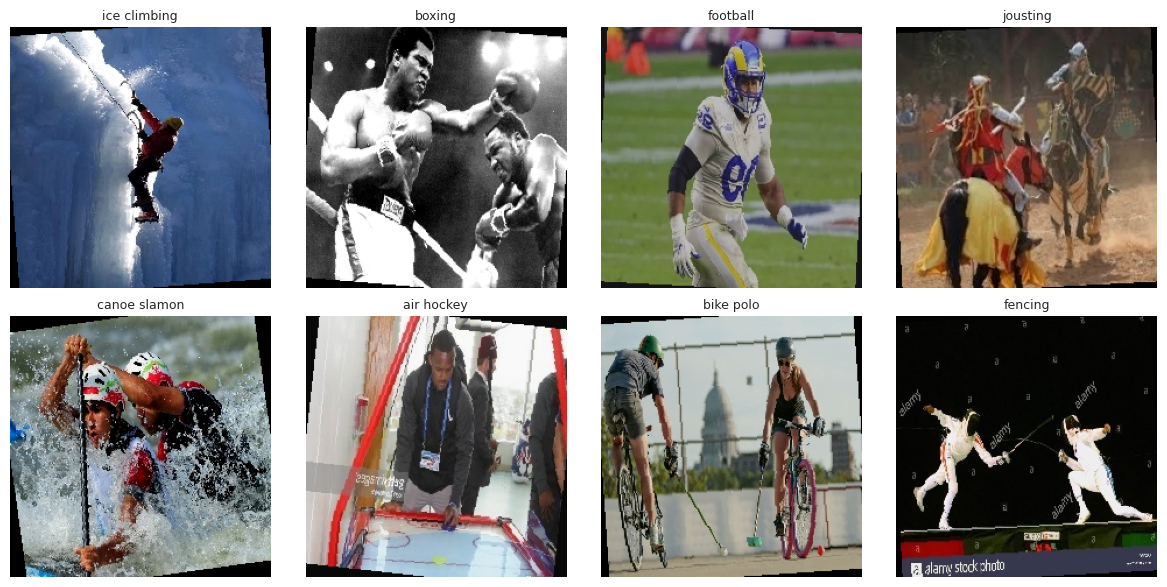

In [ ]:
# We load 1 batch into DataLoader
images, labels = next(iter(train_loader))

print("--- Checking tensors in batch ---")
print(f"Shape of image tensor (B, C, H, W): {images.shape}")
print(f"Shape of label tensor (B,): {labels.shape}")

# Denormalization function (inverse function to T.normalize)
inv_normalize = T.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

# We plot first 8 images from batch
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Denormalization of image
    img_denorm = inv_normalize(images[i])

    # Conversion from PyTorch (C, H, W) to Matplotlib (H, W, C) and to NumPy array
    img_np = img_denorm.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np, 0, 1)

    ax.imshow(img_np)
    class_name = train_dataset.classes[labels[i].item()]
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Popis modelu BaselineCNN

## 1. Jak model funguje a z čeho se skládá

Model **BaselineCNN** je obrázkový klasifikátor. Jeho úkolem je vzít klasický barevný obrázek (RGB, tedy 3 barevné kanály) a přiřadit ho do jedné z 100 kategórií (tříd).

Celá síť je rozdělená na tři hlavní části:
1. **Hledání vlastností (`self.features`)**: Tři bloky konvolucí, které v obrázku hledají vzory (od jednoduchých čar až po složitější tvary) a postupně zmenšují jeho rozměry.
2. **Zjednodušení (`self.pool`, `self.flatten`)**: Přípravná fáze, která výstup z obrázku zprůměruje a "vyrovná" do jednoho dlouhého řádku čísel.
3. **Rozhodování (`self.classifier`)**: Finální síť, která z připravených čísel spočítá pravděpodobnosti pro jednotlivé třídy.

---

## 2. Proč jsou použité zrovna tyto vrstvy?

### Malé filtry $3 \times 3$ s okrajem `padding=1`
Filtr $3 \times 3$ je úplný standard, který dobře chytá detaily a nepotřebuje obrovský výpočetní výkon. Parametr `padding=1` doplňuje okolo obrázku "prázdný rámeček", aby samotná konvoluce nezmenšovala jeho rozlišení – o to se stará až pooling.

### Vypnutý bias (`bias=False`)
Předpočet posunu (bias) je v konvolucích vypnutý, protože hned za nimi stojí vrstva `BatchNorm2d`. Ta v rámci svých výpočtů stejně čísla posouvá a průměruje, takže by bias v konvoluci byl zbytečný a jen by zabíral paměť.

### Batch Normalization (`nn.BatchNorm2d`)
Představuje "čistku" dat po konvoluci. Udržuje čísla v rozumných hranicích, díky čemuž se model učí rychleji, stabilněji a lépe konverguje k výsledkům.

### Více kanálů ($64 \rightarrow 128 \rightarrow 256$) a zmenšování (`MaxPool2d`)
Jak se obrázek zmenšuje (pomocí MaxPoolu), přichází o přesné informace o tom, kde přesně byl jaký pixel. Aby model tuto ztrátu vynahradil, nabírá naopak více kanálů (příznaků). Na začátku tak vidí jen jednoduché hrany, ale na konci už z nich skládá celé tvary.

### Zprůměrování na 1×1 (`nn.AdaptiveAvgPool2d`)
Místo toho, aby se do finálního rozhodování poslala celá mřížka dat, vše se zprůměruje na jeden bod pro každý kanál.
* **Výhoda 1**: Model díky tomu zvládne zpracovat libovolně velký obrázek na vstupu a nerozbije se.
* **Výhoda 2**: Drasticky to snižuje počet parametrů, takže se síť nezačne učit trénovací data zpaměti (overfitting).

### Vypadávání dat (`nn.Dropout(p=0.2)`)
Během trénování tato vrstva náhodně vypne 20 % neuronů.

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=100, p_drop=0.2):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(
            # 1. Konvoluční vrstva
            nn.Conv2d(3, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 2. Konvoluční vrstva
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 3. Konvoluční vrstva
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()

        self.classifier = nn.Sequential(
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Dropout(p=p_drop),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.flatten(x)
        return self.classifier(x)

## 4. Počty parametrů sítě (na základě torchinfo)

Celkový počet trénovatelných parametrů modelu je **554 148** (při počtu tříd `num_classes = 100`).

### Rozpad parametrů po vrstvách:

1. **První konvoluční blok:**
   * `Conv2d (3 -> 64)`: **1 728** parametrů ($3 \times 64 \times 3 \times 3$)
   * `BatchNorm2d (64)`: **128** parametrů ($64 \times 2$ trénovatelné váhy: $\gamma$ a $\beta$)

2. **Druhý konvoluční blok:**
   * `Conv2d (64 -> 128)`: **73 728** parametrů ($64 \times 128 \times 3 \times 3$)
   * `BatchNorm2d (128)`: **256** parametrů

3. **Třetí konvoluční blok:**
   * `Conv2d (128 -> 256)`: **294 912** parametrů ($128 \times 256 \times 3 \times 3$)
   * `BatchNorm2d (256)`: **512** parametrů

4. **Klasifikátor:**
   * `Linear (256 -> 512)`: **131 584** parametrů
   * `Linear (512 -> 100)`: **51 300** parametrů
   
Aktivace (`ReLU`), poolingy (`MaxPool2d`, `AdaptiveAvgPool2d`), `Flatten` ani `Dropout` neobsahují žádné trénovatelné parametry.

In [ ]:
model = BaselineCNN(num_classes=len(train_dataset.classes)).to(device)
torchinfo.summary(model)

Layer (type:depth-idx)                   Param #
BaselineCNN                              --
├─Sequential: 1-1                        --
│    └─Conv2d: 2-1                       1,728
│    └─BatchNorm2d: 2-2                  128
│    └─ReLU: 2-3                         --
│    └─MaxPool2d: 2-4                    --
│    └─Conv2d: 2-5                       73,728
│    └─BatchNorm2d: 2-6                  256
│    └─ReLU: 2-7                         --
│    └─MaxPool2d: 2-8                    --
│    └─Conv2d: 2-9                       294,912
│    └─BatchNorm2d: 2-10                 512
│    └─ReLU: 2-11                        --
│    └─MaxPool2d: 2-12                   --
├─AdaptiveAvgPool2d: 1-2                 --
├─Flatten: 1-3                           --
├─Sequential: 1-4                        --
│    └─Linear: 2-13                      131,584
│    └─ReLU: 2-14                        --
│    └─Dropout: 2-15                     --
│    └─Linear: 2-16                      51,300
Tot

# Trénovací a vyhodnocovací funkce

Kód definuje dvě hlavní funkce pro řízení celého procesu učení a testování modelu: `train_epoch` a `evaluate`.

---

## 1. Trénovací funkce (`train_epoch`)

Funkce provádí jednu kompletní epochu trénování (jeden průchod všemi daty v dataloaderu) a vrací průměrnou ztrátu (loss) a přesnost (accuracy).

### Klíčové kroky trénování:
* **Přepnutí do trénovacího režimu (`model.train()`)**: Aktivuje vrstvy, které se chovají odlišně při trénování a testování (zejména `Dropout` a `BatchNorm2d`).
* **Přenos dat na zařízení (`images.to(device)`)**: Přesune datové tenzory na GPU nebo CPU.
* **Vynulování gradientů (`optimizer.zero_grad()`)**: Vymaže staré gradienty z předchozího kroku, aby se neakumulovaly.
* **Dopředný průchod (Forward Pass)**: Provede výpočet predikcí `model(images)` a spočítá chybovou funkci `criterion(outputs, labels)`.
* **Zpětný průchod (Backward Pass) & Aktualizace vah**:
  * `loss.backward()`: Spočítá gradienty chybové funkce vůči všem parametrům sítě.
  * `optimizer.step()`: Upraví váhy sítě podle zvoleného optimátoru (např. Adam nebo SGD).
* **Počítání statistik**: Vyhodnocuje celkovou ztrátu a počet správně určených tříd (`torch.max(outputs, 1)`).

---

## 2. Vyhodnocovací funkce (`evaluate`)

Slouží k otestování modelu na validačních nebo testovacích datech.

### Odlišnosti oproti trénování:
* **Přepnutí do evaluačního režimu (`model.eval()`)**: Vypne vypadávání neuronů (`Dropout`) a zmrazí statistiky dávkové normalizace (`BatchNorm2d`).
* **Vypnutí výpočtu gradientů (`with torch.no_grad()`)**: Zamezí ukládání mezipaměti pro výpočet derivací. Zásadně tím šetří paměť GPU/RAM a zrychluje výpočet.
* **Absence zpětného průchodu**: Nevolá se `loss.backward()` ani `optimizer.step()`, protože model se v této fázi neučí.

In [ ]:
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        # zeros gradient
        optimizer.zero_grad()

        # 2nd Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass & Optimizer step (change of weights)
        loss.backward()
        optimizer.step()

        # Accumulation of metrics
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # We disable computations of gradients to save memory
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels.data).item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# Konfigurace trénování a trénovací smyčka

Tato část kódu definuje hyperparametry, inicializuje model s nastavením trénovacího prostředí a spouští hlavní trénovací cyklus přes 40 epoch.

---

## 1. Použité komponenty a zdůvodnění jejich volby

### Chybová funkce: `nn.CrossEntropyLoss()`
* **Co dělá:** Měří rozdíl mezi predikovanou pravděpodobnostní distribucí modelu a reálnou třídou.
* **Proč je zvolena:**
  * Je to standardní a nejvhodnější chybová funkce pro **vícetřídní klasifikaci**, kde každému obrázku náleží právě jedna třída.
  * Je numericky velmi stabilní a poskytuje silný gradient pro učení v situacích, kdy se model výrazně plete.

### Počet epoch: `num_epochs = 40`
* **Proč je zvolen:** Dává prostor pro učení modelu, ale zároveň neposkytuje příliš mnoho prostoru, aby se model přeučil

In [ ]:
baseline_model = BaselineCNN(num_classes=len(train_dataset.classes), p_drop=0.3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

num_epochs = 40

# Saving history for later plotting
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(baseline_model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(baseline_model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")

KeyboardInterrupt: 

In [ ]:
epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

# Loss function graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Val Loss', marker='o')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Acc', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Val Acc', marker='o')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Přehled experimentů a konfigurací

| Exp ID | Description / Architecture | Batch Size | Optimizer | Learning rate | Drop out | Transformations (Train)  | Epochy | Train Acc | Val Acc | Note |
| :---: | :---: | :---: | :---: | :---: | :--- | :---: | :---: | :---: | :---: | :---: |
| **EXP-01** | Custom CNN | 32 | Adam | 1e-3 | 0.2 | Flip, Rotation, ColorJitter | 40 | 61.69 % | 58.40 % | Bad transformations (same for training and validation dataset)
| **EXP-02** | Custom CNN | 32 | Adam | 1e-3 | 0.2 | Flip, Rotation, ColorJitter | 40 | 61.87% | 59.00% | Corrected transformations for validation dataset; model's overfitting seems to get worse with time |
| **EXP-03** | Custom CNN | 32 | Adam | 5e-4 | 0.3 | Flip, Rotation, ColorJitter | 40 | 57.54% | 58.20% | Validation curves seem to follow train curves more closely than **EXP-02** |
| **EXP-04** | Custom CNN | 64 | Adam | 5e-4 | 0.3 | Flip, Rotation, ColorJitter | 40 | 56.63% | 55.40% | Validation loss shows some overfitting with noticable amount of spikes. |
---



# Sanity Check (Zkouška správnosti pipeline)

Tento blok kódu provádí rychlou kontrolu funkčnosti celé trénovací architektury na velmi malé vzorku dat (pouze 1 batch o 16 obrázcích) před spuštěním plnohodnotného, časově náročného trénování.

---

## 1. Princip a cíl testu

Cílem testu je **přetrénovat model na nepatrném množství dat (overfit a single batch)** na 100 epoch.

* Pokud architektura, chybová funkce, zjišťování gradientů i aktualizace vah fungují správně, model by měl být schopen si 16 obrázků zapamatovat téměř dokonale.
* Přesnost (*Accuracy*) by měla dosáhnout $100\ \%$ (nebo alespoň $\ge 99\ \%$) a ztráta (*Loss*) by měla klesnout téměř k nule ($\le 0.05$).

---

## 2. Proč se tato zkouška provádí?

1. **Ověření toku gradientů (Gradient Flow)**: Ověří, že v modelu nejsou přerušené propojení (zapomenuté `backward()`, špatně definovaný `forward` průchod nebo zmrazené váhy).
2. **Kontrola správnosti datové pipeline**: Potvrdí, že dataloader předává data ve správném tvaru a datovém typu a že chybová funkce správně vyhodnocuje výsledky.
3. **Úspora času**: Pokud je v kódu nebo architektuře chyba, tento test ji odhalí během několika sekund. Zamezí se tak plýtvání časem a výpočetním výkonem GPU při běhu plného trénování na 40 epoch.

In [ ]:
SANITY_CHECK_BATCH_SIZE = 16

sanity_dataset = torch.utils.data.Subset(train_dataset, range(SANITY_CHECK_BATCH_SIZE))
sanity_loader = DataLoader(sanity_dataset, batch_size=SANITY_CHECK_BATCH_SIZE, shuffle=False)

sanity_model = BaselineCNN(num_classes=len(train_dataset.classes)).to(device)
sanity_optimizer = torch.optim.Adam(sanity_model.parameters(), lr=LEARNING_RATE)

# Training
for epoch in range(100):
    loss, acc = train_epoch(sanity_model, sanity_loader, criterion, sanity_optimizer, device)

    if (epoch + 1) % 20 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:3d}/100] - Loss: {loss:.4f} | Accuracy: {acc * 100:.2f}%")

if acc >= 0.99 and loss <= 0.05:
    print("\nSanity check: 100 %! Gradient flow is right and pipeline has no mistakes.")
else:
    print("\nSanity check failed. Check learning rate or model architecture.")

Epoch [  1/100] - Loss: 4.8530 | Accuracy: 0.00%


KeyboardInterrupt: 